# Paired spectral confirmation

SMOKE TEST ONLY: these one-step results are not scientific evidence.

Paired final validation loss differences (candidate minus baseline), seeds [2, 3]. Intervals use Student's t with Bonferroni correction across 6 prespecified comparisons, controlling family-wise coverage at least 95% under the paired t assumptions. Negative differences favor the candidate. Five seeds give imprecise intervals; the seeds replicate initialization, not validation-set sampling. Candidates were selected using earlier results; these seeds are held out from that selection. Results compare only the prespecified candidates and do not establish a global optimum.

| Steps | Experiment | Candidate | Baseline | Mean difference | Adjusted 95% family CI |
| ---: | --- | --- | --- | ---: | --- |
| 1 | linear_interpolation | alpha=0.25 | alpha=1 | -0.007736 | [-0.050281, 0.034809] |
| 1 | singular_value_clipping | upper=2×median | exact Muon | -0.002800 | [-0.020030, 0.014429] |
| 1 | selective_transformation | top 25% | all 100% | -0.005182 | [-0.045323, 0.034959] |
| 1 | low_rank_orthogonalization | top 25% | top 100% | -0.005192 | [-0.047008, 0.036625] |
| 1 | alpha_power | alpha=0.9375 | alpha=1 | -0.002896 | [-0.017394, 0.011601] |
| 1 | alpha_power | alpha=1.0625 | alpha=1 | 0.002500 | [-0.011014, 0.016014] |


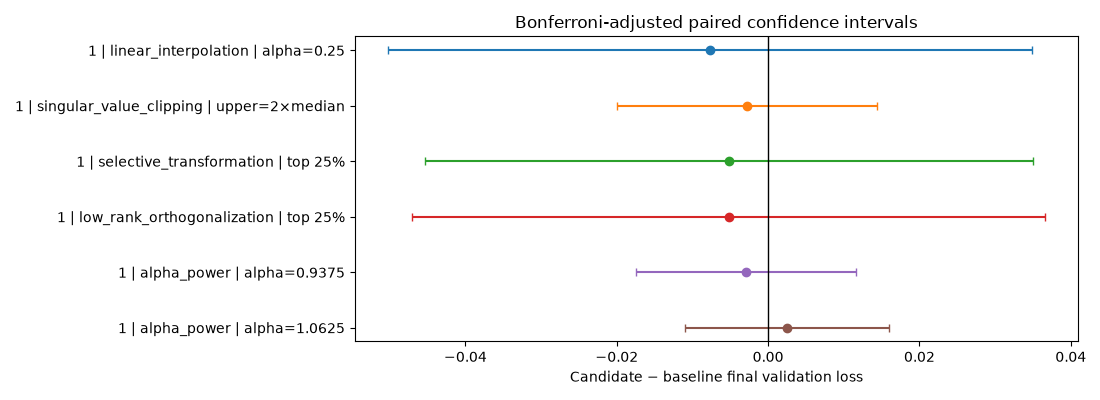

In [1]:
import json
import matplotlib.pyplot as plt
rows = json.loads('[{"experiment": "linear_interpolation", "steps": 1, "baseline": "alpha=1", "candidate": "alpha=0.25", "n": 2, "mean_difference": -0.0077362060546875, "lower": -0.05028130096216546, "upper": 0.03480888885279046}, {"experiment": "singular_value_clipping", "steps": 1, "baseline": "exact Muon", "candidate": "upper=2\\u00d7median", "n": 2, "mean_difference": -0.002800464630126953, "lower": -0.020029771043857326, "upper": 0.01442884178360342}, {"experiment": "selective_transformation", "steps": 1, "baseline": "all 100%", "candidate": "top 25%", "n": 2, "mean_difference": -0.0051822662353515625, "lower": -0.045323271875797384, "upper": 0.03495873940509426}, {"experiment": "low_rank_orthogonalization", "steps": 1, "baseline": "top 100%", "candidate": "top 25%", "n": 2, "mean_difference": -0.005191802978515625, "lower": -0.047008385986892935, "upper": 0.036624780029861685}, {"experiment": "alpha_power", "steps": 1, "baseline": "alpha=1", "candidate": "alpha=0.9375", "n": 2, "mean_difference": -0.0028963088989257812, "lower": -0.017393695691028714, "upper": 0.011601077893177153}, {"experiment": "alpha_power", "steps": 1, "baseline": "alpha=1", "candidate": "alpha=1.0625", "n": 2, "mean_difference": 0.0025000572204589844, "lower": -0.011013838507858073, "upper": 0.016013952948776042}]')
fig, ax = plt.subplots(figsize=(11, max(4, len(rows) * 0.45)))
for i, row in enumerate(rows):
    mean = row['mean_difference']
    ax.errorbar(mean, i, xerr=[[mean-row['lower']], [row['upper']-mean]], fmt='o', capsize=3)
ax.axvline(0, color='black', linewidth=1)
ax.set_yticks(range(len(rows)), [f"{r['steps']} | {r['experiment']} | {r['candidate']}" for r in rows])
ax.invert_yaxis(); ax.set_xlabel('Candidate − baseline final validation loss')
ax.set_title('Bonferroni-adjusted paired confidence intervals'); fig.tight_layout()
